# Arctic Station Power Simulator

Compare normal operation, a false under-frequency reading, and a scheduled generator outage. This is an offline training model, not a controller for real equipment.

**Start here:** Run all cells once. Then change `DURATION_S` or `SCENARIO` in **Run settings** and rerun that cell.  

## Model and breaker rule

The bus starts at **50.00 Hz**. Safe limits are **49.50 to 50.50 Hz**, inclusive. Use integer hundredths of a hertz for exact boundary decisions. Close CB101 only when both the FS101 reading and the next predicted reading with CB101 closed are in band.

In [1]:
"""Offline, one-second simulator for the Arctic station's single power bus."""

from dataclasses import dataclass

LOWER = 4950  # Frequency is stored in hundredths of a hertz (centi-Hz).
UPPER = 5050
NOMINAL = 5000
SCENARIOS = ("normal", "sensor_fault", "generator_outage")

# Key: (G101 is ON, CB101 is CLOSED). Value: centi-Hz per second.
RATE = {
    (True, True): -5,
    (True, False): 12,
    (False, True): -15,
    (False, False): 0,
}
FAULT_SECOND, FAULT_BIAS = 6, -60
OUTAGE_START, OUTAGE_END = 5, 11


@dataclass
class Trace:
    """Frequency samples include t=duration; states cover intervals only."""

    scenario: str
    true_centi: list[int]
    reported_centi: list[int]
    generator_on: list[bool]
    breaker_closed: list[bool]


def _in_band(frequency: int) -> bool:
    return LOWER <= frequency <= UPPER


def should_close(generator_on: bool, reported: int) -> bool:
    """Use only FS101 and the known generator state to decide for this second."""
    next_if_closed = reported + RATE[generator_on, True]
    return _in_band(reported) and _in_band(next_if_closed)

## Advance and record one second at a time

At each integer second, the scenario sets G101, FS101 takes a sample, and the breaker decision applies over the following one-second interval. The final frequency sample does not add an extra interval.

In [2]:
def _read_sensor(scenario: str, second: int, actual: int) -> int:
    if scenario == "sensor_fault" and second == FAULT_SECOND:
        return actual + FAULT_BIAS
    return actual


def simulate(duration_s: int = 30, scenario: str = "normal") -> Trace:
    """Run the named scenario for a positive integer number of seconds."""
    if type(duration_s) is not int or duration_s < 1:
        raise ValueError("duration_s must be a positive integer")
    if scenario not in SCENARIOS:
        raise ValueError(f"scenario must be one of {', '.join(SCENARIOS)}")

    trace = Trace(scenario, [NOMINAL], [], [], [])
    for second in range(duration_s):
        actual = trace.true_centi[-1]
        reported = _read_sensor(scenario, second, actual)
        on = not (
            scenario == "generator_outage" and OUTAGE_START <= second < OUTAGE_END
        )
        closed = should_close(on, reported)

        trace.reported_centi.append(reported)
        trace.generator_on.append(on)
        trace.breaker_closed.append(closed)
        trace.true_centi.append(actual + RATE[on, closed])

    final = _read_sensor(scenario, duration_s, trace.true_centi[-1])
    trace.reported_centi.append(final)
    return trace


def summarize(trace: Trace) -> dict:
    """Count connected intervals and out-of-band frequency samples."""
    duration = len(trace.breaker_closed)
    connected = sum(trace.breaker_closed)
    return {
        "duration_s": duration,
        "connected_s": connected,
        "connected_pct": 100 * connected / duration,
        "true_min_hz": min(trace.true_centi) / 100,
        "true_max_hz": max(trace.true_centi) / 100,
        "true_outside": sum(not _in_band(v) for v in trace.true_centi),
        "fs101_outside": sum(not _in_band(v) for v in trace.reported_centi),
    }

## Draw the three time-aligned plots

FS101 is the solid line, and the dashed lines mark the limits. The fault case adds a dotted true-frequency line and marks the bad reading. The two state plots use steps rather than interpolated transitions.

In [3]:
def plot_trace(trace: Trace):
    """Return a Matplotlib figure with three time-aligned panels."""
    import matplotlib.pyplot as plt

    seconds = range(len(trace.true_centi))
    reported = [v / 100 for v in trace.reported_centi]
    actual = [v / 100 for v in trace.true_centi]
    lower, upper = LOWER / 100, UPPER / 100

    fig, (freq, gen, breaker) = plt.subplots(
        3, 1, sharex=True, figsize=(10, 6.2), layout="constrained",
        gridspec_kw={"height_ratios": [2.6, 1, 1]},
    )
    title = trace.scenario.replace("_", " ").capitalize()
    fig.suptitle(f"Arctic station | {title}", fontsize=17, fontweight="bold")

    freq.axhspan(lower, upper, color="#01696F", alpha=0.07)
    freq.axhline(upper, color="#80543A", linestyle="--", label="Safe limits")
    freq.axhline(lower, color="#80543A", linestyle="--")
    freq.plot(seconds, reported, color="#01696F", linewidth=2, label="FS101")
    if reported != actual:
        freq.plot(
            seconds, actual, color="#34445A", linestyle=":", linewidth=2,
            label="True frequency",
        )
        bad = [t for t in seconds if reported[t] != actual[t]]
        freq.scatter(
            bad, [reported[t] for t in bad], color="#A13544", marker="x",
            s=56, zorder=4, label="Injected error",
        )
        for t in bad:
            at_right = t >= 0.85 * seconds[-1]
            freq.annotate(
                f"{reported[t]:.2f} Hz", (t, reported[t]),
                (-8 if at_right else 8, 7), ha="right" if at_right else "left",
                textcoords="offset points", color="#8E2C3B",
            )
    freq.set_ylabel("Frequency (Hz)")
    freq.set_yticks([lower, NOMINAL / 100, upper], ["49.50", "50.00", "50.50"])
    freq.set_ylim(min(49.38, min(reported) - 0.10), 50.66)
    freq.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=4, frameon=False)

    for ax, states, labels, name in (
        (gen, trace.generator_on, ["OFF", "ON"], "G101"),
        (breaker, trace.breaker_closed, ["OPEN", "CLOSED"], "CB101"),
    ):
        ax.stairs(states, seconds, baseline=None, color="#34445A", linewidth=2)
        ax.set_yticks([0, 1], labels)
        ax.set_ylim(-0.25, 1.25)
        ax.set_ylabel(name)

    for ax in (freq, gen, breaker):
        ax.grid(axis="x", color="#DDE3E6", linewidth=0.7)
        ax.spines[["top", "right"]].set_visible(False)
    breaker.set_xlim(0, seconds[-1])
    breaker.set_xlabel("Elapsed time (s)")
    return fig

## Run settings

| Scenario | What to look for |
| --- | --- |
| `normal` | First normal opening at 10 s and reclosing at 11 s |
| `sensor_fault` | FS101 reads 49.10 Hz at 6 s, opening CB101 even though true frequency is 49.70 Hz |
| `generator_outage` | G101 is OFF from 5 s until 11 s; CB101 opens at 6 s and recloses at 11 s |

Use 30 s to compare all presets. Load connected means CB101 is CLOSED, not that usable voltage was verified. Frequency-sample counts include the final sample.

Scenario: generator_outage | Duration: 30 s
Load connected: 20 s (66.7%)
True frequency: 49.50 to 50.00 Hz
Samples outside limits: true 0, FS101 0


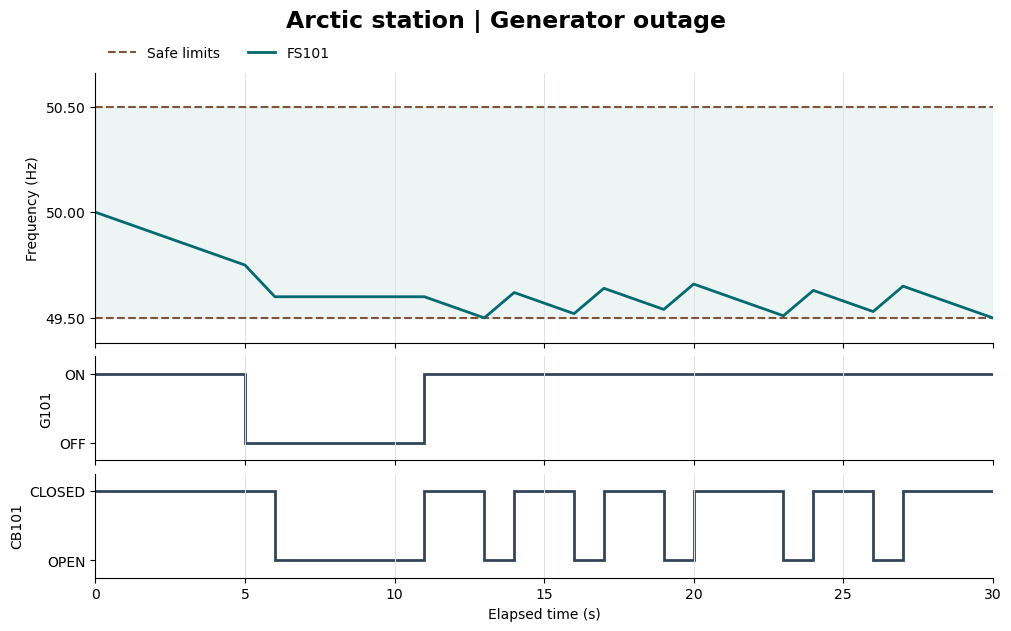

In [4]:
DURATION_S = 30
SCENARIO = "generator_outage"  # "normal", "sensor_fault", or "generator_outage"

trace = simulate(DURATION_S, SCENARIO)
stats = summarize(trace)
print(f"Scenario: {SCENARIO} | Duration: {DURATION_S} s")
print(f"Load connected: {stats['connected_s']} s ({stats['connected_pct']:.1f}%)")
print(
    f"True frequency: {stats['true_min_hz']:.2f} to "
    f"{stats['true_max_hz']:.2f} Hz"
)
print(
    f"Samples outside limits: true {stats['true_outside']}, "
    f"FS101 {stats['fs101_outside']}"
)

fig = plot_trace(trace)
fname = "my-drill-"+SCENARIO
fig.savefig(fname+".png", dpi=180, bbox_inches="tight")
import matplotlib.pyplot as plt
plt.show()